# ChiNeutro: ajuste de mT5 / mT0 (encoder-decoder) en Colab T4

Ajusta un modelo encoder-decoder para traducir español de Chile a español neutro con el **split oficial del grupo**
(`data/entrenamiento/splits/split_oficial.csv`: 3.184 train / 399 val / 397 test) y deja las predicciones en el
formato de `evaluacion/` (`id_mistral, frase_chilena, prediccion`).

**Cómo usarlo**
1. Entorno de ejecución → Cambiar tipo → **T4 GPU**.
2. Ajusta la celda de configuración (`MODELO_ID`, `MODO`, `LORA_R`...).
3. Ejecutar todo. Los checkpoints y predicciones se guardan en Drive (`MyDrive/chineutro_mt5/<NOMBRE>/`). Si Colab se
   desconecta, vuelve a ejecutar todo y el entrenamiento retoma desde el último checkpoint.

**Decisiones**
- **Mismo prompt que la baseline de mT0** (`INSTRUCCION_CHAT` de `models/gemma4/comun.py`), así mT0 sin ajuste vs
  ajustado es una comparación justa.
- **fp32 en T4**: mT5/mT0 dan NaN en fp16 y la T4 no tiene bf16 nativo. En A100 se usa bf16 automáticamente.
- **Generación greedy y primera línea**, igual que la baseline.
- **val** para comparar configuraciones. **test** solo para el resultado final (con juez, en tu computador).

In [1]:
%pip install -q -U "transformers>=4.56" "peft>=0.13" accelerate sacrebleu bert-score==0.3.13
%pip install -q sentencepiece "protobuf<7"
%pip uninstall -q -y torchao   # el torchao 0.10 de Colab rompe a peft al crear el LoRA; no se usa

In [2]:
import torch
assert torch.cuda.is_available(), "No hay GPU: Entorno de ejecución -> Cambiar tipo -> T4 GPU"
p = torch.cuda.get_device_properties(0)
BF16 = torch.cuda.get_device_capability(0)[0] >= 8      # A100/L4 sí, T4 no
print(f"GPU: {p.name} | {p.total_memory / 1e9:.0f} GB | bf16 nativo: {BF16}")

GPU: Tesla T4 | 16 GB | bf16 nativo: False


## Configuración

In [3]:
# Modelo de partida
MODELO_ID = "google/mt5-large"   # "bigscience/mt0-large" | "google/mt5-large" | "google/mt5-base"
MODO = "lora"                        # "lora" (recomendado en T4) | "full" (solo con mt5-base en T4)

# LoRA: mismos valores que el paso 2 de Gemma (r16, alpha 32) para poder comparar
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
# Atención (q, k, v, o) y MLP (wi_0, wi_1, wo) del encoder y del decoder, como "atencion+mlp" en Gemma
LORA_MODULOS = ["q", "k", "v", "o", "wi_0", "wi_1", "wo"]

# Entrenamiento
LR = 5e-4 if MODO == "lora" else 3e-4   # T5 tolera LR más altos que los LLM
EPOCAS = 6                              # se queda con la mejor época según la pérdida de validación
LOTE = 8                               # si da OOM: LOTE = 8 y ACUM = 2
ACUM = 2
SEED = 42

MAX_LEN_IN, MAX_LEN_OUT, MAX_NEW_TOKENS = 128, 96, 96

# Repo
REPO_URL = "https://github.com/matiaraos/NLP-ChiNeutro.git"
RAMA = "baseline"                       # la que tiene el split oficial y evaluacion/

corto = MODELO_ID.split("/")[-1].replace("-", "_")
NOMBRE = f"{corto}_{MODO}_r{LORA_R}" if MODO == "lora" else f"{corto}_full"
print("Corrida:", NOMBRE)

Corrida: mt5_large_lora_r16


## Drive y repo

In [4]:
import os, sys, subprocess
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
DIR_DRIVE = Path("/content/drive/MyDrive/chineutro_mt5") / NOMBRE
DIR_CKPT = DIR_DRIVE / "checkpoints"
DIR_PRED = DIR_DRIVE / "predicciones"
for d in (DIR_CKPT, DIR_PRED):
    d.mkdir(parents=True, exist_ok=True)

# Si el repo es privado: agrega un secreto de Colab llamado GITHUB_TOKEN (llave a la izquierda) con un token de
# GitHub con permiso de lectura. Si es público, no hace falta.
RAIZ = Path("/content/NLP-ChiNeutro")
if not RAIZ.exists():
    url = REPO_URL
    try:
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        url = REPO_URL.replace("https://", f"https://{token}@")
    except Exception:
        pass
    r = subprocess.run(["git", "clone", "-q", "-b", RAMA, url, str(RAIZ)], capture_output=True, text=True)
    assert r.returncode == 0, "No pude clonar el repo (¿privado? agrega el secreto GITHUB_TOKEN)"
sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout)

Mounted at /content/drive
90fa379 feat: baseline de modelos sin ajuste en test (Gemma 4 E4B base/-it, Qwen3.5 4B, mT0 large, Opus)



## 1. Datos (split oficial)

In [5]:
import pandas as pd
from evaluacion import cargar_split

por_split = {s: cargar_split(s) for s in ("train", "val", "test")}
tamanos = {s: len(d) for s, d in por_split.items()}
print(tamanos)
assert tamanos == {"train": 3184, "val": 399, "test": 397}, "El split no es el oficial"

# Ninguna frase chilena puede repetirse entre splits
frases = {s: set(d.frase_chilena.str.strip().str.lower()) for s, d in por_split.items()}
assert not (frases["train"] & frases["val"]) and not (frases["train"] & frases["test"]) \
    and not (frases["val"] & frases["test"]), "fuga entre splits"

# Mismo prompt que la baseline de mT0 (models/gemma4/comun.py)
sys.path.insert(0, str(RAIZ / "models/gemma4"))
from comun import INSTRUCCION_CHAT
def entrada(frase):
    return INSTRUCCION_CHAT.format(chilena=frase.strip())
print(entrada(por_split["train"].frase_chilena[0]))

{'train': 3184, 'val': 399, 'test': 397}
Traduce la siguiente frase del español de Chile al español neutro. Responde solo con la traducción.

Oye, necesito hablar contigo, recién me cayó la teja con lo de la plata.


In [6]:
from transformers import AutoTokenizer
from datasets import Dataset

tok = AutoTokenizer.from_pretrained(MODELO_ID)

def a_dataset(df):
    x = tok([entrada(f) for f in df.frase_chilena], max_length=MAX_LEN_IN, truncation=True)
    y = tok(text_target=[n.strip() for n in df.frase_neutralizada], max_length=MAX_LEN_OUT, truncation=True)
    return Dataset.from_dict({"input_ids": x["input_ids"], "attention_mask": x["attention_mask"],
                              "labels": y["input_ids"]})

ds_train, ds_val = a_dataset(por_split["train"]), a_dataset(por_split["val"])
largo_in = max(len(i) for i in ds_train["input_ids"])
largo_out = max(len(l) for l in ds_train["labels"])
print(f"tokens máx: entrada {largo_in}, salida {largo_out}")
assert largo_in < MAX_LEN_IN and largo_out < MAX_LEN_OUT, "algún ejemplo se truncó: sube MAX_LEN_IN/OUT"

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

tokens máx: entrada 66, salida 47


## 2. Modelo

In [7]:
from transformers import AutoModelForSeq2SeqLM, set_seed

set_seed(SEED)
dtype = torch.bfloat16 if BF16 else torch.float32       # nunca fp16 con mT5/mT0
modelo = AutoModelForSeq2SeqLM.from_pretrained(MODELO_ID, dtype=dtype)
modelo.config.use_cache = False

if MODO == "lora":
    from peft import LoraConfig, get_peft_model
    modelo = get_peft_model(modelo, LoraConfig(task_type="SEQ_2_SEQ_LM", r=LORA_R, lora_alpha=LORA_ALPHA,
                                               lora_dropout=LORA_DROPOUT, target_modules=LORA_MODULOS))
    modelo.print_trainable_parameters()
else:
    print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters()) / 1e6:.0f} M")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 4.92GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.92GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/560 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

trainable params: 18,284,544 || all params: 1,247,865,856 || trainable%: 1.4653


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


## 3. Entrenamiento

Evalúa la pérdida en val al final de cada época y se queda con la mejor. Checkpoints en Drive: si Colab se corta,
vuelve a ejecutar todo y retoma.

In [8]:
import math
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, DataCollatorForSeq2Seq

pasos_totales = math.ceil(len(ds_train) / (LOTE * ACUM)) * EPOCAS
args = Seq2SeqTrainingArguments(
    output_dir=str(DIR_CKPT),
    per_device_train_batch_size=LOTE,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=ACUM,
    num_train_epochs=EPOCAS,
    learning_rate=LR,
    lr_scheduler_type="cosine",
    warmup_steps=int(0.05 * pasos_totales),
    optim="adamw_torch" if MODO == "lora" else "adafactor",
    bf16=BF16,
    fp16=False,
    gradient_checkpointing=(MODO == "full"),
    logging_steps=20,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    report_to="none",
    seed=SEED,
)
trainer = Seq2SeqTrainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                         data_collator=DataCollatorForSeq2Seq(tok, label_pad_token_id=-100))

hay_ckpt = any(DIR_CKPT.glob("checkpoint-*"))
print("Retomando desde checkpoint" if hay_ckpt else "Entrenamiento desde cero")
trainer.train(resume_from_checkpoint=hay_ckpt)
trainer.save_model(str(DIR_DRIVE / "modelo_final"))
tok.save_pretrained(str(DIR_DRIVE / "modelo_final"))

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Entrenamiento desde cero


Epoch,Training Loss,Validation Loss
1,2.329237,0.837309
2,1.961026,0.740963
3,1.674375,0.669951
4,1.413544,0.643778
5,1.437522,0.620250
6,1.281700,0.624768


('/content/drive/MyDrive/chineutro_mt5/mt5_large_lora_r16/modelo_final/tokenizer_config.json',
 '/content/drive/MyDrive/chineutro_mt5/mt5_large_lora_r16/modelo_final/tokenizer.json')

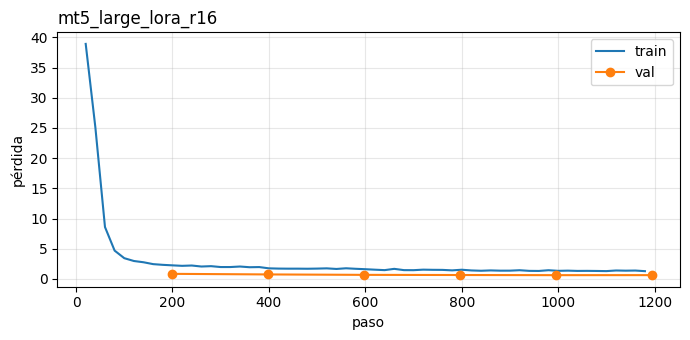

Mejor checkpoint: /content/drive/MyDrive/chineutro_mt5/mt5_large_lora_r16/checkpoints/checkpoint-995 | eval_loss: 0.6202504634857178


In [9]:
import math, json
import matplotlib.pyplot as plt

hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
assert not any(math.isnan(l) for _, l in tr + ev), "La pérdida dio NaN: revisa que no esté en fp16"

plt.figure(figsize=(7, 3.5))
plt.plot(*zip(*tr), label="train")
plt.plot(*zip(*ev), "o-", label="val")
plt.xlabel("paso"); plt.ylabel("pérdida"); plt.title(NOMBRE, loc="left"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(DIR_DRIVE / "curva_perdida.png", dpi=150); plt.show()
print("Mejor checkpoint:", trainer.state.best_model_checkpoint, "| eval_loss:", trainer.state.best_metric)
json.dump(hist, open(DIR_DRIVE / "historial.json", "w"), indent=1)

## 4. Predicciones (val y test)

In [10]:
modelo = trainer.model.eval()
modelo.config.use_cache = True

def traducir(frases, bs=32):
    salidas = []
    for i in range(0, len(frases), bs):
        x = tok([entrada(f) for f in frases[i:i + bs]], return_tensors="pt", padding=True,
                truncation=True, max_length=MAX_LEN_IN).to(modelo.device)
        with torch.no_grad():
            out = modelo.generate(input_ids=x["input_ids"], attention_mask=x["attention_mask"],
                                  do_sample=False, num_beams=1, max_new_tokens=MAX_NEW_TOKENS)
        # igual que la baseline: primera línea
        salidas += [s.strip().split("\n")[0].strip() for s in tok.batch_decode(out, skip_special_tokens=True)]
    return salidas

RUTAS = {}
for s in ("val", "test"):
    df = por_split[s][["id_mistral", "frase_chilena"]].copy()
    df["prediccion"] = traducir(df.frase_chilena.tolist())
    RUTAS[s] = DIR_PRED / f"predicciones_{NOMBRE}_{s}.csv"
    df.to_csv(RUTAS[s], index=False)
    print(f"{s}: {RUTAS[s].name} | vacías: {(df.prediccion == '').sum()} "
          f"| copia literal: {(df.prediccion.str.strip() == df.frase_chilena.str.strip()).mean():.1%}")

val: predicciones_mt5_large_lora_r16_val.csv | vacías: 0 | copia literal: 4.3%
test: predicciones_mt5_large_lora_r16_test.csv | vacías: 0 | copia literal: 2.3%


In [11]:
# Ejemplos de val para revisar a ojo
ej = por_split["val"][["termino", "frase_chilena", "frase_neutralizada"]].copy()
ej["prediccion"] = pd.read_csv(RUTAS["val"]).prediccion
pd.set_option("display.max_colwidth", 120)
display(ej.sample(12, random_state=SEED))

,termino,frase_chilena,frase_neutralizada,prediccion
198,parlanchin,"Yo soy parlanchín, en las entrevistas de trabajo me tengo que controlar harto.","Yo soy hablador, en las entrevistas de trabajo me tengo que controlar mucho.","Yo soy hablador, en las entrevistas de trabajo me tengo que controlar mucho."
349,Gorrear,Al Pato lo gorrearon tres veces y todavía sigue con la mina.,A Pato le pusieron los cuernos tres veces y todavía sigue con esa chica.,Pato lo gorrearon tres veces y todavía sigue con la chica.
33,con pica,"El abogado metió la demanda con pica, quería que la empresa pagara por lo que le hicieron.",El abogado presentó la demanda con afán de venganza; quería que la empresa pagara por lo que le hicieron.,"El abogado metió la demanda con rabia, quería que la empresa pagara por lo que le hicieron."
208,pegote,"La polola del Mati es súper pegote, ni a la pichanga lo deja ir solo.","La novia de Mati lo sigue a todas partes, ni al partido de fútbol con sus amigos lo deja ir solo.","La novia de Mati es muy mentirosa, ni a la fiesta lo deja ir solo."
93,sarpao,"Ese loco anda sarpao, mejor no lo miremos ni le hablemos.","Ese tipo anda agresivo, mejor no lo miremos ni le hablemos.","Ese tipo anda muy entrometido, mejor no lo miremos ni le hablemos."
84,Sacar la cresta,"Bájate de ese techo altiro, te vai a sacar la cresta si te resbalai.","Bájate de ese techo ahora mismo, te vas a dar un golpe tremendo si te resbalas.","Bájate de ese techo enseguida, te vas a romper el culo si te resbalas."
374,junta,"Esta semana no voy a la junta, tengo que entregar una pega el lunes.","Esta semana no voy a la reunión, tengo que entregar un trabajo el lunes.","Esta semana no voy a la reunión, tengo que entregar un trabajo el lunes."
94,se bugeo,Se me bugeó el cerebro en la prueba y no me acordé de ninguna fórmula.,Se me bloqueó la mente en el examen y no me acordé de ninguna fórmula.,Se me falló el cerebro en la prueba y no me acordé de ninguna fórmula.
222,Piola,"Quédate piola con lo del carrete, que mi mamá no se puede enterar.","No digas nada de lo de la fiesta, que mi mamá no se puede enterar.","Quédate atenta con lo del partido de fútbol, que mi mamá no se puede enterar."
126,ta mal pelao el chancho,"Los de arriba ganan millones y los profes una miseria, ta mal pelao el chancho en este país.","Los de arriba ganan millones y los profesores una miseria, la riqueza está mal repartida en este país.","Los de arriba ganan millones y los profesores una miseria, estoy mal hecho el país."


## 5. Métricas automáticas en val (sin juez)

BLEU, % de términos chilenos retenidos y BERTScore con el pipeline del grupo. Úsalas para comparar configuraciones.
El juez (Opus vía Claude Code) se corre después en tu computador, sobre test, con la configuración ya elegida.

In [12]:
import gc
del trainer, modelo
gc.collect(); torch.cuda.empty_cache()

from evaluacion import evaluar
resumen, _ = evaluar(str(RUTAS["val"]), juez=False)
print(json.dumps(resumen, ensure_ascii=False, indent=2))

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-large
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


-> /content/drive/MyDrive/chineutro_mt5/mt5_large_lora_r16/predicciones/predicciones_mt5_large_lora_r16_val_evaluacion.json
-> /content/drive/MyDrive/chineutro_mt5/mt5_large_lora_r16/predicciones/predicciones_mt5_large_lora_r16_val_por_frase.csv
{
  "n": 399,
  "bleu": 61.3,
  "terminos_retenidos_%": 12.8,
  "bertscore_f1": 0.7837,
  "bertscore_contra": "referencia"
}
